# Экзаменационная задача №1. Оценка экономической эффективности внедрения облачной CRM

**Курс:** Экономика информатизации (лекция №1 «Экономические основы информатизации»)
**Студент:** Солдатов Сергей Юрьевич
**Группа:** ПИ4-1
**Дата:** 2026-11-17

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №01: ОЦЕНКА ЭКОНОМИЧЕСКОЙ ЭФФЕКТИВНОСТИ
#                             ВНЕДРЕНИЯ ОБЛАЧНОЙ CRM
# ======================================================================
# Дата: 2026-11-17
# Студент: Солдатов Сергей Юрьевич
# Группа: ПИ4-1
# ======================================================================

# Подключаем библиотеки: numpy/pandas — расчеты и таблицы, matplotlib — графики
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Единый стиль графиков: светлый фон, тонкая сетка, без лишних рамок
plt.rcParams.update({
    "figure.figsize": (9, 4.8),
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
})

# Цвета: синий — выгоды/основной ряд, оранжевый — затраты/альтернативный ряд
C_BLUE, C_ORANGE, C_AQUA, C_GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"

# Папка для сохранения графиков и итоговых показателей
FIG_DIR = os.path.join("..", "reports", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

MLN = 1_000_000  # для перевода рублей в миллионы

# Формат вывода чисел в таблицах pandas
pd.options.display.float_format = "{:,.2f}".format

## 0. Экономическая постановка задачи

**Проблема.** Компания «ТехноПром» решает, внедрять ли облачную CRM-систему в отделе продаж
(15 менеджеров). CRM — типичная ИТ-инвестиция: затраты на нее очевидны и считаются легко
(лицензии, потери на обучение), а выгоды распределены во времени и частично нематериальны.

**Актуальность.** Это прямая иллюстрация темы лекции №1: информатизация дает эффект не
автоматически (парадокс производительности Солоу), поэтому решение об инвестициях в ИТ
нужно обосновывать расчетом денежных потоков, а не верой в технологию.

**Цель.** Определить, выгодно ли внедрение CRM на горизонте 3 лет.

**Задачи:**
1. оценить прямой эффект — экономию фонда оплаты труда и дополнительный доход от роста продаж;
2. оценить затраты — лицензии и потери периода адаптации;
3. рассчитать прирост чистой прибыли по годам, NPV, срок окупаемости и ROI;
4. проверить устойчивость вывода и проанализировать нематериальные эффекты и парадокс Солоу.

## 1. Исходные данные

### 1.1. Параметры проекта (из условия задачи)

In [2]:
# Все исходные данные собраны в одном словаре, чтобы их было легко менять в сценариях
BASE = {
    "n_managers": 15,            # количество менеджеров, чел.
    "salary_month": 120_000,     # средняя зарплата менеджера, руб./мес.
    "routine_share": 0.30,       # доля рабочего времени на рутинные операции (без CRM)
    "time_saving": 0.20,         # экономия времени на рутинных операциях после внедрения CRM
    "sales_growth": 0.08,        # рост продаж после внедрения (умеренный прогноз)
    "revenue_year": 72 * MLN,    # текущий годовой оборот отдела продаж, руб.
    "license_user_year": 24_000, # стоимость облачной CRM на пользователя в год, руб.
    "adaptation_months": 1,      # потеря времени на адаптацию (обучение), мес.
    "horizon_years": 3,          # горизонт оценки, лет
    "discount_rate": 0.12,       # ставка дисконтирования
    "tax_rate": 0.20,            # налог на прибыль
}

# Таблица исходных данных для отчета
source_table = pd.DataFrame({
    "Параметр": [
        "Количество менеджеров, чел.", "Средняя зарплата, руб./мес.",
        "Доля времени на рутину (без CRM)", "Экономия времени на рутине с CRM",
        "Рост продаж после внедрения", "Годовой оборот отдела, млн руб.",
        "Лицензия CRM, руб./чел. в год", "Период адаптации, мес.",
        "Горизонт оценки, лет", "Ставка дисконтирования", "Налог на прибыль",
    ],
    "Значение": [
        "15", "120 000", "30%", "20%", "8% в год", "72", "24 000", "1", "3", "12%", "20%",
    ],
})
display(source_table)

,Параметр,Значение
0,"Количество менеджеров, чел.",15
1,"Средняя зарплата, руб./мес.",120 000
2,Доля времени на рутину (без CRM),30%
3,Экономия времени на рутине с CRM,20%
4,Рост продаж после внедрения,8% в год
5,"Годовой оборот отдела, млн руб.",72
6,"Лицензия CRM, руб./чел. в год",24 000
7,"Период адаптации, мес.",1
8,"Горизонт оценки, лет",3
9,Ставка дисконтирования,12%


### 1.2. Справочные данные и принятые допущения

Условие задачи оставляет несколько мест, которые можно понять по-разному. Ниже зафиксировано,
как именно они трактуются в базовом расчете, и почему.

| № | Допущение | Обоснование |
|---|---|---|
| Д1 | Экономия 20% относится к **рутинному** времени, то есть высвобождается 30% × 20% = 6% рабочего времени | В условии сказано «экономия времени *на рутинных операциях*» |
| Д2 | Высвобожденное время оценивается по зарплате (без страховых взносов) | Ставка взносов в условии не задана; это осторожная оценка |
| Д3 | Рост продаж 8% — это превышение оборота над уровнем «без CRM» в каждом году, то есть +5,76 млн руб. ежегодно | Умеренный прогноз; вариант с накопительным ростом проверен в разделе 3.2 |
| Д4 | Дополнительный доход от роста продаж в базовом расчете целиком идет в прирост прибыли до налога | Маржинальность продаж в условии не задана, а задание требует считать именно «дополнительный доход». Влияние маржи проверено в анализе чувствительности |
| Д5 | Потери адаптации = месячный фонд оплаты труда отдела (15 × 120 000 руб.), относятся к 1-му году | «Потеря времени — 1 месяц»; время оцениваем так же, как в Д2, — по зарплате. Это верхняя граница потерь |
| Д6 | CRM облачная: капитальных затрат нет, лицензии оплачиваются ежегодно | Модель SaaS (OPEX вместо CAPEX) |
| Д7 | Денежные потоки приходят в конце каждого года; налог 20% начисляется на положительный прирост прибыли | Стандартное упрощение для NPV |

### 1.3. Дополнительные условия

Для проверки устойчивости результата дополнительно рассматриваются: маржинальность
дополнительных продаж 20% (условное значение для сценария) и неполная реализация эффектов
(сценарий «парадокса Солоу»).

## 2. Математическая модель

**Прямые эффекты (в год):**

- экономия ФОТ: $E_{ФОТ} = n \cdot s \cdot 12 \cdot d_{рут} \cdot e$, где $n$ — число менеджеров, $s$ — зарплата в месяц,
  $d_{рут}$ — доля рутины, $e$ — экономия времени на рутине;
- дополнительный доход: $E_{прод} = R \cdot g \cdot m$, где $R$ — оборот, $g$ — рост продаж, $m$ — доля дополнительной выручки,
  которая превращается в прибыль (в базовом расчете $m = 1$).

**Затраты:**

- лицензии: $C_{лиц} = n \cdot c_{лиц}$ в год;
- потери адаптации (только 1-й год): $C_{адапт} = n \cdot s \cdot t_{адапт}$.

**Прирост чистой прибыли в году $t$:**

$$\Delta П_t = (E_{ФОТ} + E_{прод} - C_{лиц} - C_{адапт,t}) \cdot (1 - T),$$

где $T$ — ставка налога на прибыль.

**Показатели эффективности:**

$$NPV = \sum_{t=1}^{3} \frac{\Delta П_t}{(1+r)^t}, \qquad ROI = \frac{\sum Выгоды - \sum Затраты}{\sum Затраты},$$

простой срок окупаемости — момент, когда накопленный денежный поток становится неотрицательным.

**Почему эти методы.** NPV учитывает стоимость денег во времени и является основным критерием
для многолетних проектов (лекция №1, п. 6.4). ROI дает быструю относительную оценку отдачи.
Срок окупаемости показывает, как быстро возвращаются вложения, то есть характеризует риск.

## 3. Расчеты

### 3.1. Расчетная функция

In [3]:
def evaluate_crm(p, margin=1.0, effect_realization=None, saving_realization=1.0):
    """Рассчитывает денежные потоки и показатели эффективности проекта CRM.

    p                  — словарь исходных данных;
    margin             — доля дополнительной выручки, превращающаяся в прибыль (1.0 = по условию);
    effect_realization — доля эффектов, реализованная в каждом году (None = 100% во все годы);
    saving_realization — доля высвобожденного времени, реально превращенная в деньги.
    """
    years = np.arange(1, p["horizon_years"] + 1)
    if effect_realization is None:
        effect_realization = np.ones(len(years))
    effect_realization = np.asarray(effect_realization, dtype=float)

    # --- Прямые эффекты ---
    payroll_year = p["n_managers"] * p["salary_month"] * 12            # годовой ФОТ отдела
    freed_time = p["routine_share"] * p["time_saving"]                 # доля высвобожденного времени
    saving_year = payroll_year * freed_time * saving_realization       # экономия ФОТ в год
    extra_revenue = p["revenue_year"] * p["sales_growth"]              # дополнительная выручка в год
    extra_income = extra_revenue * margin                              # ее вклад в прибыль

    # --- Затраты ---
    license_year = p["n_managers"] * p["license_user_year"]            # лицензии в год
    adaptation = p["n_managers"] * p["salary_month"] * p["adaptation_months"]  # потери адаптации

    # --- Потоки по годам ---
    benefits = (saving_year + extra_income) * effect_realization       # выгоды по годам
    costs = np.full(len(years), float(license_year))                   # затраты по годам
    costs[0] += adaptation                                             # адаптация — в 1-й год
    profit_before_tax = benefits - costs
    tax = np.maximum(profit_before_tax, 0) * p["tax_rate"]             # налог только с прибыли
    net_profit = profit_before_tax - tax                               # прирост чистой прибыли
    discount = 1 / (1 + p["discount_rate"]) ** years                   # коэффициенты дисконтирования
    discounted = net_profit * discount

    # --- Итоговые показатели ---
    npv = discounted.sum()
    roi_pretax = (benefits.sum() - costs.sum()) / costs.sum()          # ROI по формуле лекции
    roi_net = net_profit.sum() / costs.sum()                           # ROI по чистой прибыли

    return {
        "years": years, "payroll_year": payroll_year, "freed_time": freed_time,
        "saving_year": saving_year, "extra_revenue": extra_revenue, "extra_income": extra_income,
        "license_year": license_year, "adaptation": adaptation,
        "benefits": benefits, "costs": costs, "profit_before_tax": profit_before_tax,
        "tax": tax, "net_profit": net_profit, "discount": discount, "discounted": discounted,
        "npv": npv, "roi_pretax": roi_pretax, "roi_net": roi_net,
    }


# Базовый расчет строго по условию задачи
res = evaluate_crm(BASE)

### 3.2. Прямой эффект от внедрения CRM (задание 1)

In [4]:
# Экономия на заработной плате
print("1) Экономия на заработной плате")
print(f"   Годовой ФОТ отдела: 15 × 120 000 × 12 = {res['payroll_year']:,.0f} руб.")
print(f"   Высвобождаемое время: 30% × 20% = {res['freed_time']:.0%} рабочего времени")
print(f"   Экономия ФОТ в год: {res['saving_year']:,.0f} руб.")
print(f"   Это эквивалент {BASE['n_managers'] * res['freed_time']:.1f} ставки менеджера")

# Дополнительный доход от роста продаж
print("\n2) Дополнительный доход от роста продаж")
print(f"   72 000 000 × 8% = {res['extra_revenue']:,.0f} руб. в год")

# Проверка альтернативной трактовки: рост 8% накапливается год к году
compound = [BASE["revenue_year"] * ((1 + BASE["sales_growth"]) ** t - 1) for t in res["years"]]
print("\n   Справочно, если бы рост 8% накапливался год к году:")
for t, v in zip(res["years"], compound):
    print(f"   год {t}: +{v / MLN:.2f} млн руб.")
print("   В базовом расчете используется более осторожный вариант: +5,76 млн руб. ежегодно.")

print(f"\nИтого прямой эффект: {(res['saving_year'] + res['extra_income']) / MLN:.3f} млн руб. в год")

1) Экономия на заработной плате
   Годовой ФОТ отдела: 15 × 120 000 × 12 = 21,600,000 руб.
   Высвобождаемое время: 30% × 20% = 6% рабочего времени
   Экономия ФОТ в год: 1,296,000 руб.
   Это эквивалент 0.9 ставки менеджера

2) Дополнительный доход от роста продаж
   72 000 000 × 8% = 5,760,000 руб. в год

   Справочно, если бы рост 8% накапливался год к году:
   год 1: +5.76 млн руб.
   год 2: +11.98 млн руб.
   год 3: +18.70 млн руб.
   В базовом расчете используется более осторожный вариант: +5,76 млн руб. ежегодно.

Итого прямой эффект: 7.056 млн руб. в год


### 3.3. Затраты на внедрение (задание 2)

In [5]:
licenses_total = res["license_year"] * BASE["horizon_years"]
print(f"Лицензии в год: 15 × 24 000 = {res['license_year']:,.0f} руб.")
print(f"Лицензии за 3 года: {licenses_total:,.0f} руб.")
print(f"Потери периода адаптации (1 месяц ФОТ отдела): 15 × 120 000 = {res['adaptation']:,.0f} руб.")
print(f"Совокупные затраты за 3 года: {res['costs'].sum():,.0f} руб.")

Лицензии в год: 15 × 24 000 = 360,000 руб.
Лицензии за 3 года: 1,080,000 руб.
Потери периода адаптации (1 месяц ФОТ отдела): 15 × 120 000 = 1,800,000 руб.
Совокупные затраты за 3 года: 2,880,000 руб.


### 3.4. Финансовые показатели эффективности (задание 3)

In [6]:
# Таблица денежных потоков по годам, млн руб.
cash_flow = pd.DataFrame({
    "Экономия ФОТ": np.full(3, res["saving_year"]),
    "Доп. доход от продаж": np.full(3, res["extra_income"]),
    "Лицензии": -np.full(3, res["license_year"]),
    "Потери адаптации": -np.array([res["adaptation"], 0, 0]),
    "Прирост прибыли до налога": res["profit_before_tax"],
    "Налог на прибыль (20%)": -res["tax"],
    "Прирост чистой прибыли": res["net_profit"],
    "Коэфф. дисконтирования": res["discount"] * MLN,
    "Дисконтированный поток": res["discounted"],
}, index=[f"Год {t}" for t in res["years"]]).T / MLN
cash_flow["Итого"] = cash_flow.sum(axis=1)
cash_flow.loc["Коэфф. дисконтирования", "Итого"] = np.nan
display(cash_flow.round(4))

,Год 1,Год 2,Год 3,Итого
Экономия ФОТ,1.30,1.30,1.30,3.89
Доп. доход от продаж,5.76,5.76,5.76,17.28
Лицензии,-0.36,-0.36,-0.36,-1.08
Потери адаптации,-1.80,0.00,0.00,-1.80
Прирост прибыли до налога,4.90,6.70,6.70,18.29
Налог на прибыль (20%),-0.98,-1.34,-1.34,-3.66
Прирост чистой прибыли,3.92,5.36,5.36,14.63
Коэфф. дисконтирования,0.89,0.80,0.71,NaN
Дисконтированный поток,3.50,4.27,3.81,11.58


In [7]:
# Простой срок окупаемости: строим помесячный накопленный поток.
# Лицензия оплачивается в начале каждого года, месяц 1 — адаптация (эффекта нет),
# со 2-го месяца эффекты поступают равномерно.
months = np.arange(1, BASE["horizon_years"] * 12 + 1)
monthly_benefit = (res["saving_year"] + res["extra_income"]) / 12
monthly_flow = np.full(len(months), monthly_benefit)
monthly_flow[0] = -res["adaptation"]                 # месяц адаптации: потери вместо эффекта
monthly_flow[::12] -= res["license_year"]            # оплата лицензий в начале года
cumulative = monthly_flow.cumsum()
payback_month = int(months[cumulative >= 0][0])      # первый месяц с неотрицательным итогом

# Оценка по формуле: вложения первого года / среднемесячный эффект
first_year_outlay = res["adaptation"] + res["license_year"]
payback_formula = first_year_outlay / monthly_benefit

print(f"Прирост чистой прибыли по годам, млн руб.: "
      + ", ".join(f"{v / MLN:.4f}" for v in res["net_profit"]))
print(f"Суммарный прирост чистой прибыли за 3 года: {res['net_profit'].sum() / MLN:.4f} млн руб.")
print(f"NPV проекта (r = 12%): {res['npv'] / MLN:.3f} млн руб.")
print(f"Простой срок окупаемости: {payback_formula:.1f} мес. эффекта после месяца адаптации, "
      f"то есть вложения возвращаются на {payback_month}-м месяце проекта")
print(f"ROI (выгоды − затраты) / затраты, до налога: {res['roi_pretax']:.0%}")
print(f"ROI по чистой прибыли (после налога): {res['roi_net']:.0%}")

Прирост чистой прибыли по годам, млн руб.: 3.9168, 5.3568, 5.3568
Суммарный прирост чистой прибыли за 3 года: 14.6304 млн руб.
NPV проекта (r = 12%): 11.580 млн руб.
Простой срок окупаемости: 3.7 мес. эффекта после месяца адаптации, то есть вложения возвращаются на 5-м месяце проекта
ROI (выгоды − затраты) / затраты, до налога: 635%
ROI по чистой прибыли (после налога): 508%


### 3.5. Анализ чувствительности и сценарии

Базовый расчет опирается на допущения Д3–Д5. Проверяем, сохранится ли вывод, если они не выполнятся.

In [8]:
# Сценарии:
# A — по условию задачи;
# B — в прибыль превращается только маржа с дополнительных продаж (условно 20%);
# C — «парадокс Солоу»: маржа 20%, в деньги превращается половина высвобожденного времени,
#     в 1-й год реализуется только половина эффектов (временной лаг освоения системы).
scenarios = {
    "A. Базовый (по условию)": evaluate_crm(BASE),
    "B. Маржа доп. продаж 20%": evaluate_crm(BASE, margin=0.20),
    "C. Консервативный (Солоу)": evaluate_crm(BASE, margin=0.20, saving_realization=0.5,
                                               effect_realization=[0.5, 1.0, 1.0]),
}
scenario_table = pd.DataFrame({
    name: {
        "Выгоды за 3 года, млн руб.": s["benefits"].sum() / MLN,
        "Затраты за 3 года, млн руб.": s["costs"].sum() / MLN,
        "Чистая прибыль за 3 года, млн руб.": s["net_profit"].sum() / MLN,
        "NPV, млн руб.": s["npv"] / MLN,
        "ROI до налога, %": s["roi_pretax"] * 100,
    } for name, s in scenarios.items()
}).T
display(scenario_table.round(2))

,"Выгоды за 3 года, млн руб.","Затраты за 3 года, млн руб.","Чистая прибыль за 3 года, млн руб.","NPV, млн руб.","ROI до налога, %"
A. Базовый (по условию),21.17,2.88,14.63,11.58,635.00
B. Маржа доп. продаж 20%,7.34,2.88,3.57,2.73,155.00
C. Консервативный (Солоу),4.50,2.88,1.04,0.61,56.25


In [9]:
# Чувствительность NPV к росту продаж при разной марже
growth_grid = np.linspace(0, 0.12, 49)
npv_by_growth = {}
for margin in (1.0, 0.20):
    npv_by_growth[margin] = np.array([
        evaluate_crm({**BASE, "sales_growth": g}, margin=margin)["npv"] for g in growth_grid
    ])

# NPV при нулевом росте продаж: окупает ли CRM одна только экономия времени?
npv_zero_growth = evaluate_crm({**BASE, "sales_growth": 0.0})["npv"]
print(f"NPV при нулевом росте продаж (только экономия времени): {npv_zero_growth / MLN:.3f} млн руб.")

# Точка безубыточности по экономии времени при нулевом росте продаж (метод бисекции)
lo, hi = 0.0, 1.0
for _ in range(60):
    mid = (lo + hi) / 2
    if evaluate_crm({**BASE, "sales_growth": 0.0, "time_saving": mid})["npv"] > 0:
        hi = mid
    else:
        lo = mid
breakeven_saving = hi
print(f"Минимальная экономия рутинного времени для NPV = 0 без роста продаж: {breakeven_saving:.1%}")

# Чувствительность NPV к изменению каждого параметра на ±20% («торнадо»)
tornado_params = {
    "Рост продаж": "sales_growth",
    "Оборот отдела": "revenue_year",
    "Экономия времени на рутине": "time_saving",
    "Доля рутины": "routine_share",
    "Зарплата менеджера": "salary_month",
    "Цена лицензии": "license_user_year",
    "Ставка дисконтирования": "discount_rate",
}
tornado = []
for label, key in tornado_params.items():
    low = evaluate_crm({**BASE, key: BASE[key] * 0.8})["npv"]
    high = evaluate_crm({**BASE, key: BASE[key] * 1.2})["npv"]
    tornado.append((label, low / MLN, high / MLN))
tornado_table = pd.DataFrame(tornado, columns=["Параметр", "NPV при −20%", "NPV при +20%"])
tornado_table["Размах"] = (tornado_table["NPV при +20%"] - tornado_table["NPV при −20%"]).abs()
tornado_table = tornado_table.sort_values("Размах", ascending=False).reset_index(drop=True)
display(tornado_table.round(3))

NPV при нулевом росте продаж (только экономия времени): 0.358 млн руб.
Минимальная экономия рутинного времени для NPV = 0 без роста продаж: 17.4%


,Параметр,NPV при −20%,NPV при +20%,Размах
0,Рост продаж,9.37,13.79,4.43
1,Оборот отдела,9.37,13.79,4.43
2,Ставка дисконтирования,12.10,11.10,1.01
3,Экономия времени на рутине,11.08,12.08,1.00
4,Доля рутины,11.08,12.08,1.00
5,Зарплата менеджера,11.34,11.82,0.48
6,Цена лицензии,11.72,11.44,0.28


### 3.6. Визуализация результатов

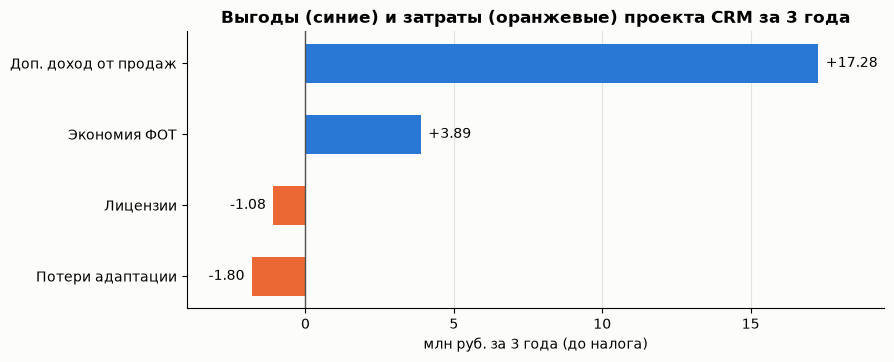

In [10]:
# График 1. Из чего складывается эффект: выгоды и затраты за 3 года
components = pd.Series({
    "Доп. доход от продаж": res["extra_income"] * 3,
    "Экономия ФОТ": res["saving_year"] * 3,
    "Лицензии": -res["license_year"] * 3,
    "Потери адаптации": -res["adaptation"],
}) / MLN
fig, ax = plt.subplots(figsize=(9, 3.6))
colors = [C_BLUE if v > 0 else C_ORANGE for v in components]
bars = ax.barh(components.index[::-1], components.values[::-1], color=colors[::-1], height=0.55)
for bar, v in zip(bars, components.values[::-1]):
    ax.text(v + (0.25 if v > 0 else -0.25), bar.get_y() + bar.get_height() / 2,
            f"{v:+.2f}", va="center", ha="left" if v > 0 else "right")
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_xlim(-4, 19.5)
ax.set_xlabel("млн руб. за 3 года (до налога)")
ax.set_title("Выгоды (синие) и затраты (оранжевые) проекта CRM за 3 года")
ax.grid(axis="y", visible=False)
fig.savefig(os.path.join(FIG_DIR, "01_components.png"), dpi=160, bbox_inches="tight")
plt.show()

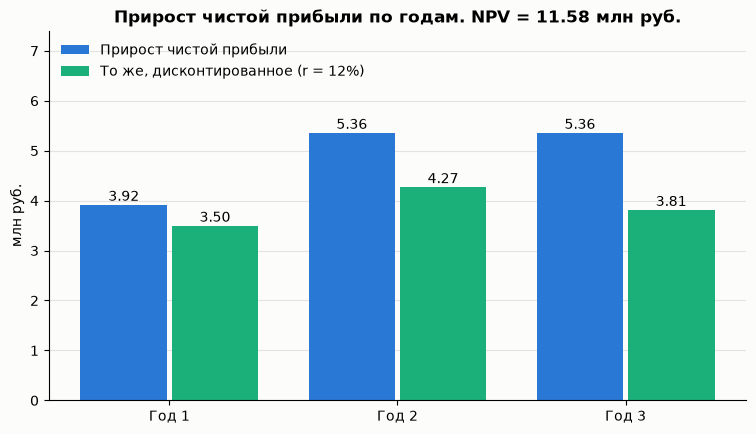

In [11]:
# График 2. Прирост чистой прибыли по годам: номинальный и дисконтированный
fig, ax = plt.subplots()
x = np.arange(3)
b1 = ax.bar(x - 0.2, res["net_profit"] / MLN, width=0.38, color=C_BLUE, label="Прирост чистой прибыли")
b2 = ax.bar(x + 0.2, res["discounted"] / MLN, width=0.38, color=C_AQUA,
            label="То же, дисконтированное (r = 12%)")
for bars in (b1, b2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.08,
                f"{bar.get_height():.2f}", ha="center")
ax.set_xticks(x, [f"Год {t}" for t in res["years"]])
ax.set_ylabel("млн руб.")
ax.set_ylim(0, 7.4)
ax.set_title(f"Прирост чистой прибыли по годам. NPV = {res['npv'] / MLN:.2f} млн руб.")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
fig.savefig(os.path.join(FIG_DIR, "01_net_profit.png"), dpi=160, bbox_inches="tight")
plt.show()

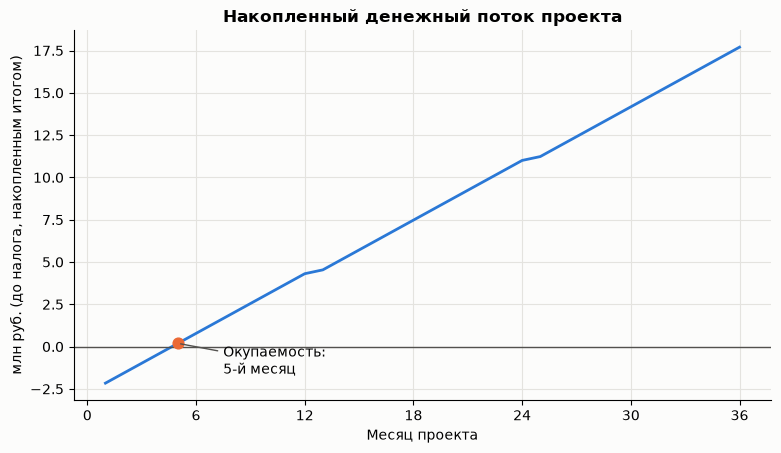

In [12]:
# График 3. Накопленный денежный поток по месяцам и точка окупаемости
fig, ax = plt.subplots()
ax.plot(months, cumulative / MLN, color=C_BLUE, linewidth=2)
ax.axhline(0, color="#52514e", linewidth=1)
ax.scatter([payback_month], [cumulative[payback_month - 1] / MLN], color=C_ORANGE, s=60, zorder=3)
ax.annotate(f"Окупаемость:\n{payback_month}-й месяц", (payback_month, cumulative[payback_month - 1] / MLN),
            xytext=(payback_month + 2.5, -1.6), arrowprops={"arrowstyle": "-", "color": "#52514e"})
ax.set_xlabel("Месяц проекта")
ax.set_ylabel("млн руб. (до налога, накопленным итогом)")
ax.set_title("Накопленный денежный поток проекта")
ax.set_xticks(range(0, 37, 6))
fig.savefig(os.path.join(FIG_DIR, "01_payback.png"), dpi=160, bbox_inches="tight")
plt.show()

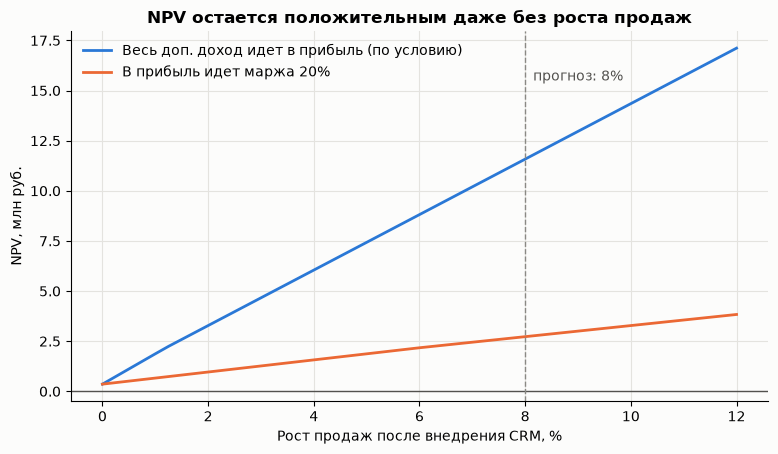

In [13]:
# График 4. Чувствительность NPV к росту продаж при разной марже
fig, ax = plt.subplots()
ax.plot(growth_grid * 100, npv_by_growth[1.0] / MLN, color=C_BLUE, linewidth=2,
        label="Весь доп. доход идет в прибыль (по условию)")
ax.plot(growth_grid * 100, npv_by_growth[0.20] / MLN, color=C_ORANGE, linewidth=2,
        label="В прибыль идет маржа 20%")
ax.axhline(0, color="#52514e", linewidth=1)
ax.axvline(8, color=C_GRAY, linewidth=1, linestyle="--")
ax.text(8.15, 15.5, "прогноз: 8%", color="#52514e")
ax.set_xlabel("Рост продаж после внедрения CRM, %")
ax.set_ylabel("NPV, млн руб.")
ax.set_title("NPV остается положительным даже без роста продаж")
ax.legend(frameon=False, loc="upper left")
fig.savefig(os.path.join(FIG_DIR, "01_sensitivity_growth.png"), dpi=160, bbox_inches="tight")
plt.show()

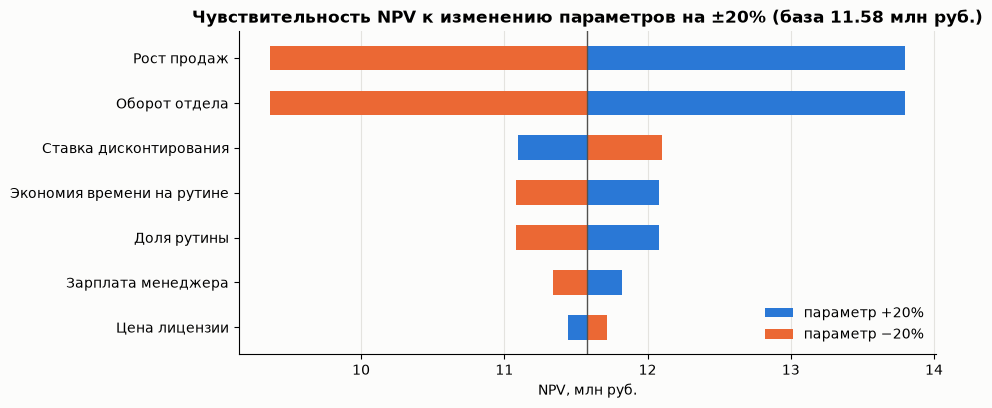

In [14]:
# График 5. «Торнадо»: какие параметры сильнее всего влияют на NPV
fig, ax = plt.subplots(figsize=(9, 4.2))
t_plot = tornado_table.iloc[::-1]
base_npv = res["npv"] / MLN
ax.barh(t_plot["Параметр"], t_plot["NPV при +20%"] - base_npv, left=base_npv,
        color=C_BLUE, height=0.55, label="параметр +20%")
ax.barh(t_plot["Параметр"], t_plot["NPV при −20%"] - base_npv, left=base_npv,
        color=C_ORANGE, height=0.55, label="параметр −20%")
ax.axvline(base_npv, color="#52514e", linewidth=1)
ax.set_xlabel("NPV, млн руб.")
ax.set_title(f"Чувствительность NPV к изменению параметров на ±20% (база {base_npv:.2f} млн руб.)")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
fig.savefig(os.path.join(FIG_DIR, "01_tornado.png"), dpi=160, bbox_inches="tight")
plt.show()

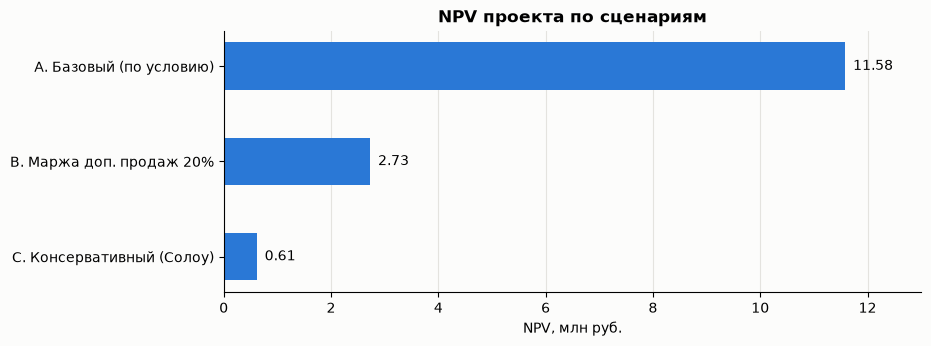

In [15]:
# График 6. NPV по сценариям
fig, ax = plt.subplots(figsize=(9, 3.4))
names = list(scenarios.keys())[::-1]
values = [scenarios[n]["npv"] / MLN for n in names]
bars = ax.barh(names, values, color=C_BLUE, height=0.5)
for bar, v in zip(bars, values):
    ax.text(v + 0.15, bar.get_y() + bar.get_height() / 2, f"{v:.2f}", va="center")
ax.set_xlim(0, 13)
ax.set_xlabel("NPV, млн руб.")
ax.set_title("NPV проекта по сценариям")
ax.grid(axis="y", visible=False)
fig.savefig(os.path.join(FIG_DIR, "01_scenarios.png"), dpi=160, bbox_inches="tight")
plt.show()

In [16]:
# Сохраняем ключевые показатели в файл — он используется при подготовке отчета
summary = {
    "payroll_year": res["payroll_year"], "freed_time": res["freed_time"],
    "saving_year": res["saving_year"], "extra_revenue": res["extra_revenue"],
    "license_year": res["license_year"], "licenses_total": licenses_total,
    "adaptation": res["adaptation"], "costs_total": res["costs"].sum(),
    "benefits_total": res["benefits"].sum(),
    "profit_before_tax": res["profit_before_tax"].tolist(), "tax": res["tax"].tolist(),
    "net_profit": res["net_profit"].tolist(), "discount": res["discount"].tolist(),
    "discounted": res["discounted"].tolist(), "npv": res["npv"],
    "roi_pretax": res["roi_pretax"], "roi_net": res["roi_net"],
    "payback_month": payback_month, "payback_formula": payback_formula,
    "npv_zero_growth": npv_zero_growth, "breakeven_saving": breakeven_saving,
    "compound": compound,
    "scenarios": {n: {"npv": s["npv"], "roi_pretax": s["roi_pretax"],
                      "net_total": s["net_profit"].sum(), "benefits": s["benefits"].sum(),
                      "net_profit": s["net_profit"].tolist()}
                  for n, s in scenarios.items()},
    "tornado": tornado_table.values.tolist(),
}
with open(os.path.join("..", "reports", "01_summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print("Показатели сохранены в reports/01_summary.json")

Показатели сохранены в reports/01_summary.json


## 4. Анализ результатов

### 4.1. Интерпретация полученных данных

- **Эффект формируют продажи, а не экономия времени.** Из 7,06 млн руб. годового эффекта 5,76 млн руб. (82%) дает рост
  продаж и только 1,30 млн руб. (18%) — высвобожденное время. Экономия 6% рабочего времени эквивалентна 0,9 ставки
  менеджера: сократить «девять десятых человека» нельзя, поэтому эта экономия станет деньгами только если менеджеры
  потратят освободившееся время на продажи.
- **Затраты малы по сравнению с выгодами.** За 3 года проект стоит 2,88 млн руб. (1,08 млн руб. лицензии и 1,80 млн руб.
  потери адаптации). Причем 62% затрат — не плата поставщику, а скрытые потери на обучение. Это типичная для ИТ-проектов
  картина: цена лицензии — меньшая часть совокупной стоимости.
- **Проект эффективен по всем критериям.** NPV = 11,58 млн руб. > 0, ROI = 635% до налога (508% по чистой прибыли),
  вложения возвращаются на 5-м месяце.
- **Вывод устойчив.** NPV положителен даже при нулевом росте продаж (0,36 млн руб.) и в консервативном сценарии
  (0,61 млн руб.). Но запас прочности в этих случаях небольшой: без роста продаж проекту достаточно недобрать экономию
  времени с 20% до 17,4%, чтобы NPV стал нулевым.

### 4.2. Сравнение с альтернативными вариантами

- **Альтернатива «не внедрять»** дает NPV = 0, то есть уступает проекту во всех трех сценариях.
- **Трактовка роста продаж.** Если 8% накапливаются год к году, эффект был бы выше (до +18,7 млн руб. в 3-й год). Базовый
  расчет использует осторожный вариант, поэтому положительный вывод не зависит от выбора трактовки.
- **Маржинальность.** Самое сильное допущение базового расчета — что весь дополнительный доход становится прибылью. При
  марже 20% NPV падает с 11,58 до 2,73 млн руб., ROI — с 635% до 155%. Проект остается выгодным, но уже не «сверхдоходным».
- **Самые влиятельные параметры** (график «торнадо»): рост продаж и оборот отдела. Цена лицензии влияет на NPV слабее
  всех остальных параметров, поэтому торговаться с поставщиком за скидку менее важно, чем обеспечить реальный рост продаж.

### 4.3. Нематериальные эффекты (задание 4)

**Нематериальные выгоды CRM, не вошедшие в расчет:**

1. *Клиентская база становится активом компании*, а не личным знанием менеджера: при увольнении сотрудника контакты и
   история сделок сохраняются. Это снижает информационную асимметрию между менеджером и компанией.
2. *Прозрачность воронки продаж*: руководитель видит, на каком этапе теряются сделки, прогноз выручки становится точнее.
3. *Качество обслуживания*: единая история общения, меньше забытых звонков и потерянных заявок, выше удержание клиентов.
4. *Накопление данных* для аналитики: сегментация клиентов, оценка эффективности каналов и менеджеров.
5. *Быстрый ввод новых сотрудников* за счет стандартизированного процесса продаж.
6. *Снижение транзакционных издержек* внутри компании: меньше согласований, отчеты формируются автоматически.

**Влияние парадокса Солоу.** Парадокс производительности («компьютеры видны везде, кроме статистики производительности»)
означает, что фактический эффект может оказаться ниже расчетного или проявиться позже:

- *временной лаг*: сначала продуктивность падает (обучение, перенос данных), эффект приходит позже. В условии на адаптацию
  отведен 1 месяц, на практике освоение CRM часто занимает несколько месяцев;
- *необходимость организационных изменений*: CRM без перестройки процесса продаж, регламентов и мотивации превращается в
  «дорогую записную книжку», а менеджеры воспринимают ее как дополнительную отчетность;
- *экономия времени не равна экономии денег*: зарплата менеджеров не уменьшится, эффект появится только при
  перераспределении времени на продажи;
- *проблема измерения*: рост продаж на 8% трудно отделить от влияния рынка, сезонности и рекламы.

Сценарий C количественно показывает эту поправку: при лаге и неполной реализации эффектов NPV снижается в 19 раз,
хотя и остается положительным.

## 5. Выводы и рекомендации

### 5.1. Ключевые выводы

1. Внедрение облачной CRM экономически целесообразно: NPV = **11,58 млн руб.**, ROI = **635%** (508% по чистой прибыли),
   окупаемость — **5-й месяц** проекта.
2. Прирост чистой прибыли: **3,92 млн руб.** в 1-й год и по **5,36 млн руб.** во 2-й и 3-й годы, всего 14,63 млн руб.
3. 82% эффекта дает рост продаж; экономия рабочего времени сама по себе лишь немного перекрывает затраты.
4. Вывод устойчив к пессимистичным допущениям, но величина эффекта сильно зависит от того, какая доля дополнительной
   выручки превращается в прибыль, и от реального роста продаж.

### 5.2. Практические рекомендации

1. **Внедрять CRM**, так как решение выгодно даже в консервативном сценарии, а облачная модель не требует капитальных
   затрат и позволяет отказаться от системы с малыми потерями.
2. **Управлять ростом продаж, а не лицензиями.** Заранее определить, на что менеджеры потратят высвобожденные 6% времени
   (дополнительные звонки, работа с «холодной» базой), и зафиксировать это в KPI.
3. **Сократить потери адаптации**, которые составляют 62% затрат: обучать группами, внедрять поэтапно, начать с пилота на
   3–5 менеджерах, не запускать в сезон пиковых продаж.
4. **Сопроводить внедрение организационными изменениями**: регламент ведения сделок, привязка мотивации к работе в CRM —
   это основной способ избежать парадокса Солоу.
5. **Измерять фактический эффект**: зафиксировать базовые показатели до внедрения (конверсия, длительность сделки, выручка
   на менеджера) и сравнить их через 6 и 12 месяцев; при отсутствии роста продаж пересмотреть решение.